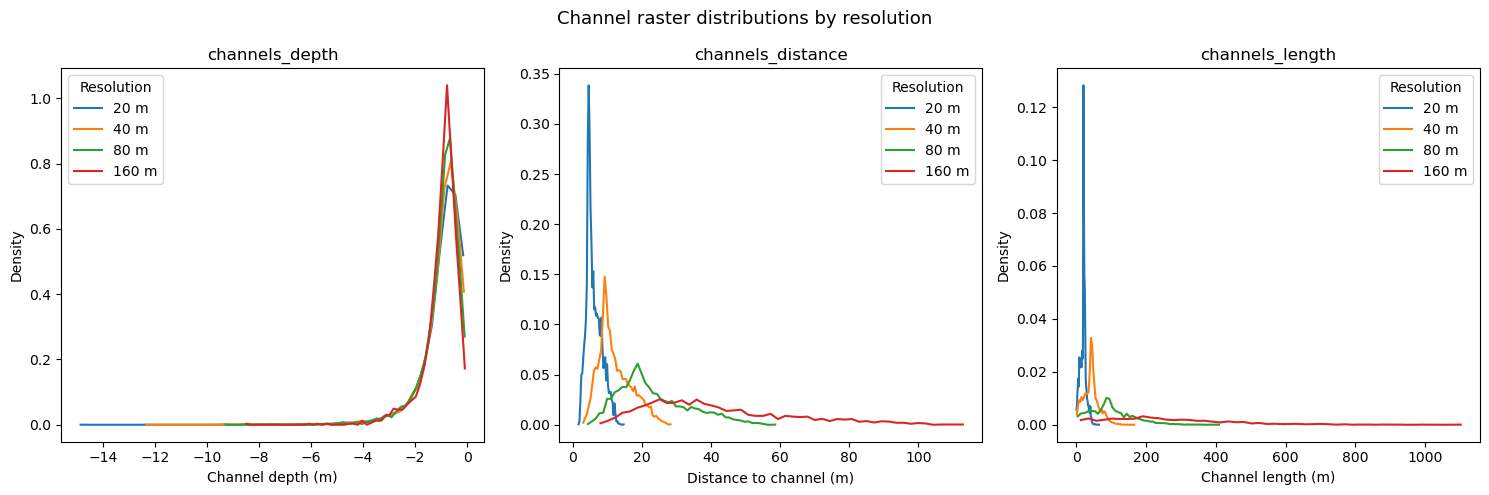

In [1]:
import numpy as np
import matplotlib.pyplot as plt

base_dir = "/Users/jpnousu/Library/CloudStorage/OneDrive-Luonnonvarakeskus/SpaFHy_RUNS/krycklan/gis/{res}m/{raster}.asc"
resolutions = [20, 40, 80, 160]
rasters = ["channels_depth", "channels_distance", "channels_length"]
xlabels = {"channels_depth": "Channel depth (m)",
            "channels_distance": "Distance to channel (m)",
            "channels_length": "Channel length (m)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, raster in zip(axes, rasters):
    for res in resolutions:
        data = np.loadtxt(base_dir.format(res=res, raster=raster), skiprows=6)
        values = data[data != -9999].ravel()
        counts, bin_edges = np.histogram(values, bins=50, density=True)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        ax.plot(bin_centers, counts, label=f"{res} m")
    ax.set_xlabel(xlabels[raster])
    ax.set_ylabel("Density")
    ax.set_title(raster)
    ax.legend(title="Resolution")

plt.suptitle("Channel raster distributions by resolution", fontsize=13)
plt.tight_layout()
plt.show()